# Solar filament images and ESAIR research context

Load the train/test data for the [Solar Filament Segmentation Challenge 2026](https://www.kaggle.com/competitions/filament-segmentation-2026/data), inspect grayscale observations, and review the supplied ESAIR research. This is a data exploration notebook, not a trained model or submission pipeline.

Run cells in order. On Kaggle, attach the competition dataset. Locally, select a Python kernel with `numpy`, `Pillow`, and `matplotlib`; uncomment the next cell if needed. Missing local data can be downloaded in the acquisition cell (approximately 751 MB uncompressed). Credentials stay outside this notebook. Images are loaded lazily rather than all at once.

In [3]:
# Uncomment if the selected notebook kernel is missing these packages.
# %pip install numpy Pillow matplotlib


In [4]:
import json
import shutil
import subprocess
import zipfile
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

COMPETITION = 'filament-segmentation-2026'
DATASET_NAME = 'MAGFiLO_1.0_Kaggle_2026'
ANNOTATION_NAME = 'MAGFiLO_1.0_Annotations_kaggle2026_train.json'
LOCAL_DATA_DIR = Path.cwd() / 'data'
DATA_ROOT_OVERRIDE = None  # Optional: Path('/absolute/path/to/MAGFiLO_1.0_Kaggle_2026')
DOWNLOAD_IF_MISSING = True
KAGGLE_CLI_OVERRIDE = None  # Optional: Path('/absolute/path/to/kaggle')
EXPECTED_SHAPE = (2048, 2048)
SEED = 2026

def find_data_root() -> Path | None:
    if DATA_ROOT_OVERRIDE is not None:
        candidates = [Path(DATA_ROOT_OVERRIDE)]
    else:
        candidates = [
            LOCAL_DATA_DIR / DATASET_NAME,
            Path.cwd() / DATASET_NAME,
            Path('/kaggle/input/competitions') / COMPETITION / DATASET_NAME,
            Path('/kaggle/input') / COMPETITION / DATASET_NAME,
        ]
    for root in candidates:
        if ((root / 'train' / 'train_images').is_dir()
                and (root / 'test' / 'test_images').is_dir()
                and (root / 'train' / ANNOTATION_NAME).is_file()):
            return root
    return None


## 1. Locate or acquire the dataset

The working local client was `~/.local/bin/kaggle` (CLI 2.2.4); the earlier Python 3.9 client returned 401. Prefer that executable over the shell default here. No credential values are read or printed. Authenticate with Kaggle and accept the competition rules yourself before downloading.

Set `DOWNLOAD_IF_MISSING = False` to prohibit downloads. Set `DATA_ROOT_OVERRIDE` for an existing dataset in another location; an invalid override fails rather than downloading elsewhere. The download is retained as a ZIP and extracted under `data/`. No test annotations are provided.

In [5]:
DATA_ROOT = find_data_root()
if DATA_ROOT is None:
    if DATA_ROOT_OVERRIDE is not None:
        raise FileNotFoundError(f'Incomplete dataset at {DATA_ROOT_OVERRIDE}')
    if not DOWNLOAD_IF_MISSING:
        raise FileNotFoundError('Attach/download the competition data or set DATA_ROOT_OVERRIDE.')
    preferred_cli = Path.home() / '.local' / 'bin' / 'kaggle'
    if KAGGLE_CLI_OVERRIDE is not None:
        cli = str(KAGGLE_CLI_OVERRIDE)
    elif preferred_cli.is_file():
        cli = str(preferred_cli)
    else:
        cli = shutil.which('kaggle')
    if cli is None:
        raise FileNotFoundError('Kaggle CLI not found. Install/configure it or attach the dataset.')
    LOCAL_DATA_DIR.mkdir(parents=True, exist_ok=True)
    print(f'Using Kaggle CLI: {cli}')
    subprocess.run([cli, 'competitions', 'download', '-c', COMPETITION,
                    '-p', str(LOCAL_DATA_DIR)], check=True)
    archive_path = LOCAL_DATA_DIR / f'{COMPETITION}.zip'
    extraction_root = LOCAL_DATA_DIR.resolve()
    with zipfile.ZipFile(archive_path) as archive:
        for member in archive.infolist():
            target = (extraction_root / member.filename).resolve()
            if not target.is_relative_to(extraction_root):
                raise ValueError(f'Unsafe archive path: {member.filename}')
        archive.extractall(extraction_root)
    DATA_ROOT = find_data_root()
    if DATA_ROOT is None:
        raise FileNotFoundError('Downloaded archive does not contain the expected dataset layout.')

TRAIN_IMAGE_DIR = DATA_ROOT / 'train' / 'train_images'
TEST_IMAGE_DIR = DATA_ROOT / 'test' / 'test_images'
ANNOTATION_PATH = DATA_ROOT / 'train' / ANNOTATION_NAME
print(f'Dataset root: {DATA_ROOT}')


Dataset root: /Users/gregorykojadinovichii/Europa Waters/Software/Kaggle/SolarFilament/data/MAGFiLO_1.0_Kaggle_2026


In [6]:
train_paths = sorted(TRAIN_IMAGE_DIR.glob('*.jpeg'))
test_paths = sorted(TEST_IMAGE_DIR.glob('*.jpeg'))
if not train_paths or not test_paths:
    raise FileNotFoundError('Train and test directories must both contain JPEG images.')
with ANNOTATION_PATH.open() as stream:
    coco = json.load(stream)
image_records = coco['images']
filament_annotations = coco['annotations']
category_names = {category['id']: category['name'] for category in coco['categories']}
records_by_filename = defaultdict(list)
annotations_by_image_id = defaultdict(list)
for record in image_records:
    records_by_filename[record['file_name']].append(record)
for annotation in filament_annotations:
    annotations_by_image_id[annotation['image_id']].append(annotation)
train_names = {path.name for path in train_paths}
test_names = {path.name for path in test_paths}
missing_files = set(records_by_filename) - train_names
if missing_files:
    raise FileNotFoundError(f'Annotations reference missing images: {sorted(missing_files)[:5]}')
if train_names & test_names:
    raise ValueError('Train and test contain overlapping filenames.')
known_ids = {record['id'] for record in image_records}
if set(annotations_by_image_id) - known_ids:
    raise ValueError('Annotations reference unknown image IDs.')
print(f'Train JPEGs: {len(train_paths):,}; test JPEGs: {len(test_paths):,}')
print(f'Annotation image records: {len(image_records):,}; filaments: {len(filament_annotations):,}')
print('Annotator records per physical image:', dict(Counter(map(len, records_by_filename.values()))))
print('Filament categories:', dict(Counter(category_names[a['category_id']] for a in filament_annotations)))
print('Categories defined in JSON:', category_names)


Train JPEGs: 707; test JPEGs: 180
Annotation image records: 1,154; filaments: 8,199
Annotator records per physical image: {1: 411, 3: 151, 2: 145}
Filament categories: {'Right': 2590, 'Unidentifiable': 3074, 'Left': 2535}
Categories defined in JSON: {1: 'Left', 2: 'Right', 3: 'Unidentifiable', 4: 'Ambiguous'}


## 2. Load train/test images and preview

These observations are 2048 x 2048, 8-bit grayscale JPEGs, not RGB inputs. `load_image` returns a single-channel `uint8` array, or `float32` in [0, 1] when requested. It preserves full resolution, validates the stored image mode/dimensions, and does not resize or apply contrast enhancement.

The API review found **707 train images, 180 test images, 1,154 annotator-specific image records, and 8,199 filament annotations**. Counts are printed from the actual files above rather than forced. Multiple annotation records can refer to the same physical JPEG: keep all their IDs, and group validation splits by filename (and preferably observing time/day) to prevent leakage. Test images have no ground-truth masks.

In [7]:
def load_image(path: Path, *, normalize: bool = False) -> np.ndarray:
    with Image.open(path) as image:
        if image.mode != 'L':
            raise ValueError(f'{path.name}: expected grayscale mode L, got {image.mode}')
        array = np.array(image, dtype=np.uint8)
    if array.shape != EXPECTED_SHAPE:
        raise ValueError(f'{path.name}: expected {EXPECTED_SHAPE}, got {array.shape}')
    if normalize:
        return array.astype(np.float32) / np.float32(255.0)
    return array

train_image = load_image(train_paths[0])
test_image = load_image(test_paths[0])
normalized_train_image = load_image(train_paths[0], normalize=True)
print('Train sample:', train_paths[0].name, train_image.shape, train_image.dtype)
print('Test sample:', test_paths[0].name, test_image.shape, test_image.dtype)
print('Normalized train range:', normalized_train_image.min(), normalized_train_image.max())


Train sample: 20110109104734Ch.jpeg (2048, 2048) uint8
Test sample: 20110120105534Ch.jpeg (2048, 2048) uint8
Normalized train range: 0.0 0.9019608


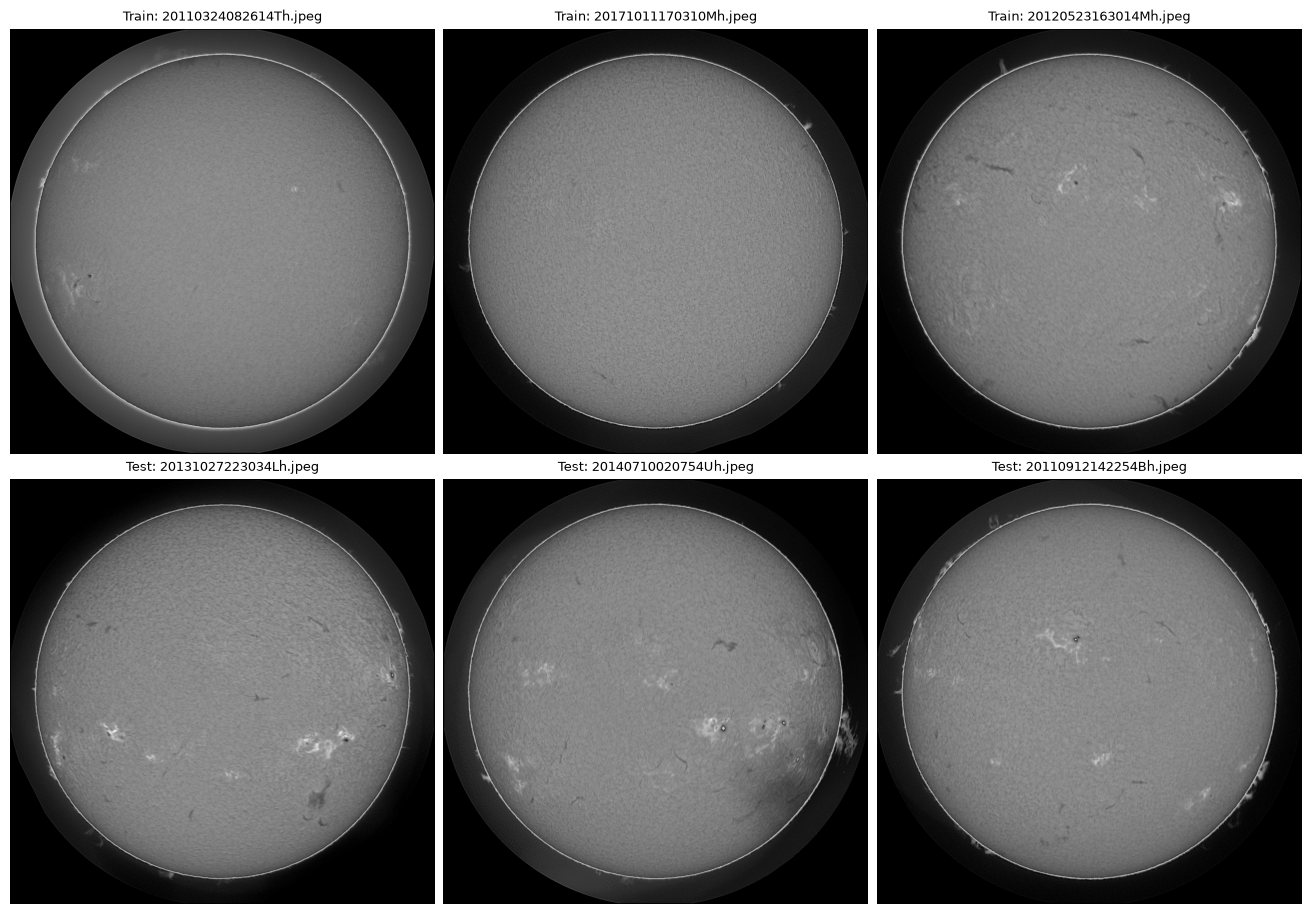

In [8]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 3, figsize=(13, 9), constrained_layout=True)
for row, (split, paths) in enumerate([('Train', train_paths), ('Test', test_paths)]):
    indices = rng.choice(len(paths), size=min(3, len(paths)), replace=False)
    for column, index in enumerate(indices):
        path = paths[int(index)]
        axes[row, column].imshow(load_image(path), cmap='gray', vmin=0, vmax=255)
        axes[row, column].set_title(f'{split}: {path.name}', fontsize=9)
    for axis in axes[row]:
        axis.axis('off')
plt.show()


## 3. ESAIR research: what the supplied sources establish

The supplied documents support two connected research directions, not a single already-validated competition solution:

- **Input quality:** detect damaged GONG H-alpha observations before downstream scientific analysis (SoftwareX 2025 and ICDMW 2025 papers).
- **Filament structure:** segment thin filaments, reconnect fragments, extract individual regions, then classify chirality (Graduate Research Fair 2026 poster).

Quality-control F1 scores are **image anomaly-classification results**, not filament segmentation scores or Kaggle leaderboard results. The poster gives qualitative segmentation comparisons and a classification plot; it does not establish a reproducible numerical competition score, training recipe, or final architecture configuration. The following summaries describe the provided material, not unobserved later work.

### A. Explainable quality control: H-Alpha Anomalyzer

**Source:** [Khazaei et al., SoftwareX 30 (2025), 102120](./ESAIRResearch/1-s2.0-S2352711025000871-main.pdf), pp. 1-4; [DOI](https://doi.org/10.1016/j.softx.2025.102120).

The team developed a lightweight grid-based quality detector for corrupt observations: clouds, oversaturation, missing/misaligned disks, occlusions, artificial maintenance images, and blur. Per-cell mean intensities are compared with learned normal ranges. Candidate percentile bounds are ranked using a one-way ANOVA F-test on normal/anomalous examples. Standardized deviations are transformed into cell-level anomaly likelihoods; an image is flagged using a likelihood threshold plus a minimum count of corrupt cells. Localized likelihood maps let domain experts inspect why a frame was flagged.

The reported evaluation used **2,000 images**: 400 for training and 1,600 for evaluation, balanced by anomaly status. It reported **F1 = 0.96, FPR = 0.04, FNR = 0.05**; threshold 0.65 and two corrupt cells were tuned for that dataset, not universal defaults. The abstract reports about ten 2048 x 2048 images/second on a modest laptop; this notebook has not benchmarked that claim.

**Competition relevance:** quality flags could support auditing, augmentation design, or training-sample weighting. Filament annotations are not corruption labels, so this dataset alone does not provide the supervision needed to refit this quality detector. Do not discard test images; every required test image still needs inference. Fine texture defects may leave cell averages normal, motivating richer quality features. This notebook does not install or reproduce Anomalyzer.

### B. Comparative anomaly detection and failure analysis

**Source:** [H-Alpha Anomalyzer: An Explainable Anomaly Detector for Solar H-Alpha Observations, ICDMW 2025](./ESAIRResearch/10712086.pdf), pp. 6-7, Tables I-II and qualitative analysis; [DOI](https://doi.org/10.1109/ICDMW69685.2025.00235).

This study compares Anomalyzer with supervised SVM, one-class SVM, and GANomaly. Its balanced experiment uses the same 70/10/20 train/validation/test split across methods. Unlike the SoftwareX evaluation, its reported Anomalyzer setting is grid size 16, likelihood threshold 0.7, and four corrupt cells. Keep these protocols separate.

| Method | Balanced anomaly F1 (Table I) | 1:5 corrupt:normal anomaly F1 (Table II) |
|---|---:|---:|
| GANomaly | 0.95 | 0.90 |
| One-class SVM | 0.80 | 0.52 |
| SVM | 0.98 | 0.82 |
| H-Alpha Anomalyzer | 0.97 | 0.90 |

The team examines operational imbalance rather than relying only on a balanced benchmark. Anomalyzer's FPR increases from 2% to 3.5%, while SVM's increases from 1.5% to approximately 8%. Limb-ring processing artifacts contribute false positives; static-noise-like corruption can evade a detector based on mean intensities. GANomaly has relatively low false positives but misses more anomalies, including obstructions.

**Pipeline implication:** evaluate both missed defects and needless rejection of useful frames, stratify by quality pattern, and inspect localized explanations. These findings motivate quality-aware segmentation experiments; they do not prove quality filtering improves this competition's segmentation metric.

### C. The 2026 segmentation and classification pipeline

**Source:** [Singh, Khazaei, Chalmers, and Ahmadzadeh, Towards a Robust Pipeline for Detection and Classification of Solar Filaments Using Machine Learning](./ESAIRPoster/GRF_Poster_04.2026.pdf), Graduate Research Fair 2026 poster, p. 1: Segmentation, Multiscale IoU Loss, Grouping, Classification, and Results panels.

The poster's pipeline is **H-alpha image → U-Net with MIoU → geometry-based grouping/ROI extraction → ConvNeXt classification**.

1. **Semantic segmentation:** U-Net predicts filament/background pixels, preserving thin structures and barbs. It does not intrinsically assign separate filament instances.
2. **Boundary-sensitive optimization:** Multiscale IoU (MIoU) compares segmentations at several resolutions/window sizes and aggregates overlap. Applying it to boundaries targets fine shape detail. The poster derives a loss from differentiable soft IoU and reports that MIoU and BF1 capture details better than other tested losses. It does not provide all implementation choices or numerical segmentation results needed to reproduce the comparison.
3. **Fragment grouping:** broken masks are post-processed using geometry. The diagram shows binary masks, spine identification, and proximity/orientation checks before grouping fragments. Exact thresholds and grouping code are not supplied; avoid treating simple connected components or arbitrary dilation as a reproduction.
4. **Classification:** grouped bounding boxes define individual filament cutouts. ConvNeXt is reported as the best classifier among the models tested. It is a convolutional architecture with modern design influences, not a vision transformer. The plot compares ground-truth, ungrouped, and post-processed bounding boxes; the authors interpret grouping as recovering regions with nearly ground-truth information. No exact accuracy or controlled ablation is claimed here from the plot.

**Competition connection:** the requested task is segmentation. Chirality classification is a separate downstream goal; category names in the training JSON do not by themselves mean that classification is required for the submission. Focus on valid instance masks and verify the live evaluation/submission rules before implementing an exporter.

## 4. Proposed improvements to test (not published results)

| Experiment | Motivation from sources | Evidence to collect |
|---|---|---|
| Grouped train/validation split | Multiple annotators can label the same JPEG | No shared filename across splits; optionally hold out observing days/sites |
| Quality audit before filtering | Anomalyzer localizes defects but can miss texture or flag limb rings | Quality-stratified segmentation errors; filtering/weighting ablation on the same validation split |
| Grayscale, full-resolution or tiled U-Net | Thin filaments and barbs are easily lost | Small/thin filament recall, boundary detail, memory/runtime, tile seam errors |
| Baseline loss vs MIoU vs BF1 | Poster motivates shape-aware training | Fixed architecture/split/seed; official-metric score plus boundary diagnostic |
| No grouping vs geometry-based grouping | Semantic masks fragment filaments | Matched instance quality, split/merge errors, nearby distinct filaments incorrectly joined |
| Optional ConvNeXt chirality stage | Poster separates segmentation and classification | Classification using ground-truth vs predicted/grouped crops; keep separate from segmentation score |

**Implementation guardrails:** preserve each annotator-specific image ID and its annotations rather than silently overwriting duplicates; choose and document a multiple-annotator training target policy. Inspect the real `segmentation` representation before rasterizing: the supplied JSON has polygon lists, even though the competition description also mentions RLE. Polygon paths need not repeat the starting point. Use a COCO-compatible decoder for masks, and nearest-neighbor interpolation for any mask resizing. Do not silently substitute empty masks on parsing errors.

Record validation splits, preprocessing, annotation policy, checkpoint, seed, post-processing thresholds, and runtime. Select all thresholds on validation data, not test/leaderboard feedback alone. Preserve predictions for every test image. Verify the current competition metric and submission format directly: the public description has changed during the challenge, and MIoU is a research objective/diagnostic, not automatically the official metric.

Next implementation stage: mask decoding and annotation overlays, grouped validation manifests, then a measured segmentation baseline. Those training stages are intentionally not implemented in this image-loading notebook.